# 03a - Avaliação da previsão sazonal de ENA do ECMWF (SEAS5)

**Pergunta:** a ENA prevista pelo ECMWF acerta a ENA que entra no PMO? Melhor que "não saber nada" (climatologia) e que
repetir o mês anterior (persistência)? A faixa de incerteza é confiável?

**Dados:** 22 rodadas (jan/2025 a out/2026), `data/raw/ecmwf_ena/`. Cada rodada cobre 7 meses (lead 0 = mês de emissão até
lead 6; a média e os percentis `vaz` vão até o lead 5). Duas abordagens: `precip` (estatística da chuva → ENA) e `vaz`
(estatística da vazão). Os 51 membros (`ECENSLTm`) são da abordagem `vaz` (a média deles difere 0,6% do `av_vaz`).
**Verdade:** ENA mensal do `ena.pdf` do PMO de cada mês (a mesma do oráculo). MLT do ECMWF ≈ MLT do ONS (0,5%).

In [1]:
import numpy as np
import pandas as pd
from IPython.display import Image, display

from forecast_bandeiras import graficos, load

pd.set_option("display.float_format", lambda v: f"{v:,.1f}")
SUBS = ["SE", "S", "NE", "N"]
est = load.ler_ecmwf_estatisticas()
mem = load.ler_ecmwf_membros()
for d in (est, mem):
    d["lead"] = (d.alvo - d.emissao).apply(lambda x: x.n)
est, mem = est[est.lead >= 0], mem[mem.lead >= 0]
base = pd.read_parquet(load.DATA_PROCESSED / "base_mensal.parquet")
base.index = base.index.to_period("M")
real_sub = pd.concat({s: base[f"ena_{s}"] for s in SUBS}, axis=1).stack().rename("real")
real_sub.index.names = ["alvo", "subsistema"]
pct_real = pd.concat({s: base[f"ena_mlt_{s}"] for s in SUBS}, axis=1)
chave = ["emissao", "alvo", "subsistema"]

## 1. Fontes de previsão (ENA por subsistema, somada no SIN)

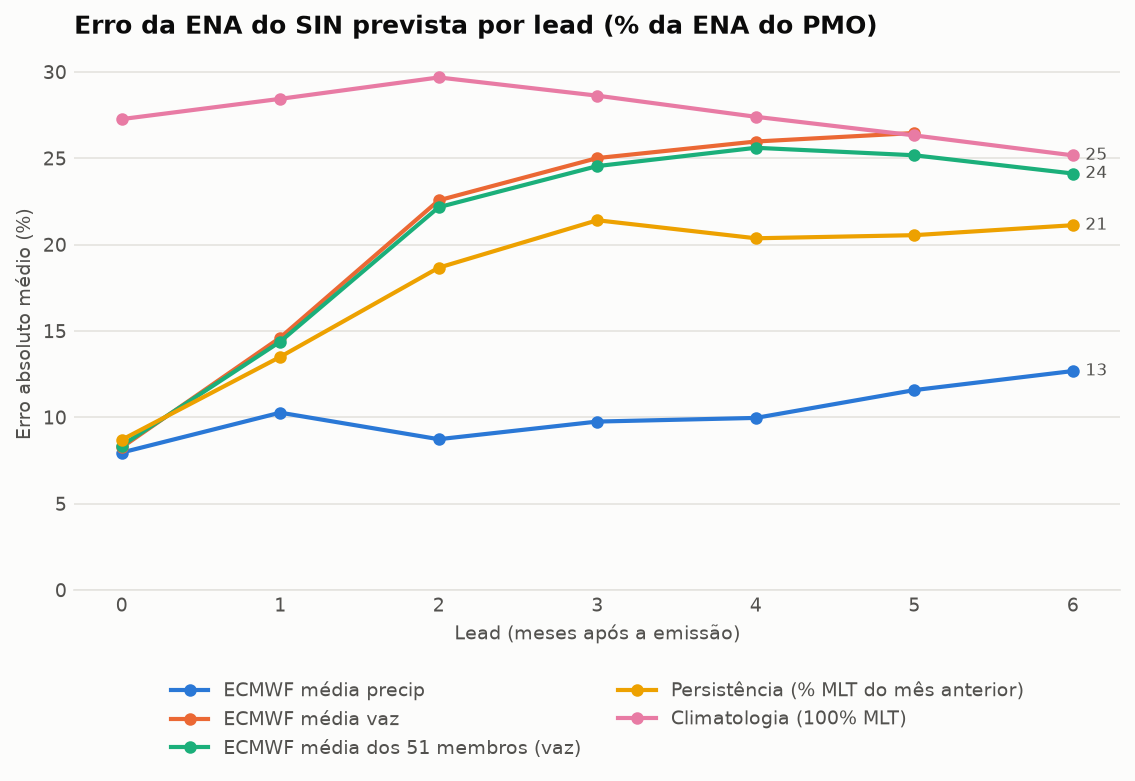

fonte,ECMWF média precip,ECMWF média vaz,ECMWF média dos 51 membros (vaz),Persistência (% MLT do mês anterior),Climatologia (100% MLT)
lead,,,,,
0,8.0,8.3,8.4,8.7,27.3
1,10.3,14.6,14.4,13.5,28.4
2,8.7,22.6,22.2,18.7,29.7
3,9.8,25.0,24.5,21.4,28.6
4,10.0,26.0,25.6,20.4,27.4
5,11.6,26.5,25.2,20.5,26.3
6,12.7,NaN,24.1,21.1,25.2


In [2]:
av_precip = est[(est.estatistica == "av") & (est.abordagem == "precip")].set_index(chave).ena
av_vaz = est[(est.estatistica == "av") & (est.abordagem == "vaz")].set_index(chave).ena
media_membros = mem.groupby(chave).ena.mean()
mlt_ecmwf = mem.groupby(chave).mlt.first()
# membros recentrados: dispersão dos 51 membros (vaz) com o centro na média precip (só produtos da rodada, sem dado realizado)
mem = mem.merge(av_precip.rename("av_precip").reset_index(), on=chave).merge(media_membros.rename("media_membros").reset_index(), on=chave)
mem["ena_recentrada"] = mem.ena * mem.av_precip / mem.media_membros
persistencia = pd.Series([v * pct_real.loc[em - 1, s] / 100 if em - 1 in pct_real.index else np.nan
                          for (em, al, s), v in mlt_ecmwf.items()], index=mlt_ecmwf.index)
fontes = {"ECMWF média precip": av_precip, "ECMWF média vaz": av_vaz, "ECMWF média dos 51 membros (vaz)": media_membros,
          "Persistência (% MLT do mês anterior)": persistencia, "Climatologia (100% MLT)": mlt_ecmwf}
linhas = []
for nome, f in fontes.items():
    d = f.rename("prev").reset_index().merge(real_sub.reset_index(), on=["alvo", "subsistema"]).dropna()
    sin = d.groupby(["emissao", "alvo"])[["prev", "real"]].sum().reset_index()
    sin["lead"] = (sin.alvo - sin.emissao).apply(lambda x: x.n)
    for lead, g in sin.groupby("lead"):
        linhas.append({"fonte": nome, "lead": lead, "n": len(g),
                       "erro": 100 * ((g.prev - g.real).abs() / g.real).mean(), "vies": 100 * ((g.prev - g.real) / g.real).mean()})
R = pd.DataFrame(linhas)
R = R[~((R.fonte == "ECMWF média vaz") & (R.lead == 6))]  # vaz só vai até o lead 5 (1 rodada isolada no lead 6)
erro = R.pivot(index="lead", columns="fonte", values="erro")[list(fontes)]
display(Image(graficos.erro_por_lead(erro, "Erro da ENA do SIN prevista por lead (% da ENA do PMO)",
                                     "ecmwf/11_erro_ena_por_lead.png", "Erro absoluto médio (%)")))
erro

In [3]:
R.pivot(index="lead", columns="fonte", values="vies")[list(fontes)]  # viés (%): + = superestima

fonte,ECMWF média precip,ECMWF média vaz,ECMWF média dos 51 membros (vaz),Persistência (% MLT do mês anterior),Climatologia (100% MLT)
lead,,,,,
0,-1.1,7.6,7.7,-0.6,22.0
1,-6.7,13.8,13.6,-1.5,23.1
2,-3.0,19.9,19.5,-3.0,24.1
3,-2.0,22.0,21.4,-6.6,22.8
4,-4.1,20.5,20.1,-9.2,21.3
5,-5.0,22.2,20.8,-11.2,19.8
6,-6.3,NaN,19.7,-11.7,17.8


Os percentis da abordagem `precip` são extremamente largos e assimétricos (ex.: SE, mar/2026: P10 = 30% e P90 = 296% da
MLT): a média funciona como previsão central, mas os percentis não servem como faixa de ENA.

## 2. Faixa de incerteza: membros originais × recentrados na média precip

In [4]:
real_sin = base.ena_sin.rename("real")
def cobertura(col):
    s = mem.groupby(["emissao", "alvo", "lead", "membro"])[col].sum().reset_index().merge(real_sin, left_on="alvo", right_index=True)
    r = s.groupby(["emissao", "alvo", "lead"]).apply(lambda g: pd.Series({
        "dentro P10–P90": g[col].quantile(.1) <= g.real.iloc[0] <= g[col].quantile(.9),
        "dentro P25–P75": g[col].quantile(.25) <= g.real.iloc[0] <= g[col].quantile(.75),
        "abaixo P10": g.real.iloc[0] < g[col].quantile(.1), "acima P90": g.real.iloc[0] > g[col].quantile(.9)}), include_groups=False)
    return r.mean().mul(100)
pd.DataFrame({"membros originais (vaz)": cobertura("ena"), "recentrados na média precip": cobertura("ena_recentrada"),
              "ideal": [80, 50, 10, 10]}, index=["dentro P10–P90", "dentro P25–P75", "abaixo P10", "acima P90"])

,membros originais (vaz),recentrados na média precip,ideal
dentro P10–P90,62.1,81.8,80
dentro P25–P75,34.8,52.3,50
abaixo P10,37.9,5.3,10
acima P90,0.0,12.9,10


## 3. Conclusões

- **A média `precip` é a melhor previsão central**: erro de 8–13% na ENA do SIN em todos os leads, viés pequeno (−1% a −7%).
  Supera com folga a climatologia (25–30%) e a persistência (9–21%, que piora com o lead).
- **A abordagem `vaz` (média e membros) é úmida demais**: viés de +8% no lead 0 a +22% nos leads 3–5, erro de 20–26%.
- **Os percentis `precip` não servem como faixa** (largos e assimétricos demais).
- **Membros recentrados na média `precip`** (dispersão dos 51 membros com o centro da média `precip`) dão uma faixa
  **calibrada**: 82% das vezes a ENA real cai entre P10 e P90 (ideal 80%) e 52% entre P25 e P75 (ideal 50%).
- Proposta para o modelo: **centro = média `precip`** (estratégia A) e **51 membros recentrados** (estratégia B).